# Photograph-Based Estimates of Plant Area and Vertical Area Distribution

## Data Description and Access
This project uses three datasets that I collected and prepared:

1. **GoPro RGB photographs:** Color photographs of submerged aquatic
   vegetation (SAV), representing several plant types. These images will
   be used to estimate total horizontal projected plant area and the
   vertical distribution of that area.

2. **GoPro image metadata:** A table containing previously determined
   blue-threshold and mean pixel-area values for each photograph.
   The blue threshold is a cutoff applied to the brightness of the blue
   channel in an RGB image to distinguish 3D-printed blue disks of known
   area from the other objects in the photograph. The mean pixel-area
   value represents the average physical area corresponding to one
   image pixel, calculated using these reference disks.

3. **Plant morphology measurements and image references:** A table for
   Susquehanna milfoil samples containing plant morphology measurements
   and references to the associated GoPro photographs. The table identifies
   reference images and individual branch images, allowing photographs
   to be linked to the corresponding plant samples and branches.

### Previously Completed Image Calibration

Each photograph includes 3D-printed blue disks of known physical area.
A blue-channel brightness threshold was used to identify the disks
and measure the number of pixels they occupied. Each disk's known
physical area was divided by its pixel count to estimate the physical
area per pixel. These estimates were averaged to obtain a mean
pixel-area value for each photograph.

The blue thresholds and resulting mean pixel-area values are stored
in the GoPro image metadata table. This project will use the existing
calibration values to convert plant pixel counts into physical area;
the disk calibration procedure will not be repeated in this notebook.

### Data Access

All three datasets are my own primary data and are available in the
`data/raw/` folder of this GitHub repository. To run this notebook,
download or clone the repository, including the contents of
`data/raw/`, and preserve its folder structure.

#### Spatial & Temporal Coverage

The milfoil samples were collected from Susquehanna Flats during
Summer 2026. Collection location and date provide context
for the samples but are not explanatory variables in this project.
The analysis focuses on projected plant area and its vertical
distribution rather than geographic or temporal patterns.

The relevant spatial resolution is the physical size represented
by each image pixel, as recorded in the GoPro metadata table.
Image-specific calibration values allow measurements from photographs
with different scales to be expressed in consistent physical units.

The following figures and summaries will describe sample coverage,
image resolution, and connections among the datasets. Branch photograph
counts per plant (IDX) will show how photographic sampling is distributed
across plants, while calibration plots will show variation in physical
pixel size among photographs.

Image identifiers will be used to examine overlap among the photographs,
GoPro metadata, and morphology records. Collection and photography dates,
where available, will describe temporal coverage and whether the records
represent the same sampling events. Image-specific calibration values
will allow area measurements to be expressed in consistent physical units
before they are combined.

All quantitative figures will include descriptive titles, labeled axes,
and units where applicable.

In [17]:
# Import standard libraries

from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

In [18]:
# Load the morphology measurements and image references.


# Replace these paths with your image folder and metadata file.
image_folder = Path(r"C:\Users\mguar\OneDrive - Old Dominion University\PhD Hat\Research_Summer2026\GoProImages")
metadata_file = Path(r"C:\Users\mguar\OneDrive - Old Dominion University\PhD Hat\Research_Summer2026\MorphoMassMeasurements\Script1_Product\Susquehanna_milfoil_GoProMetadata.xlsx")
morphmeasures_file = Path(
    r"C:\Users\mguar\OneDrive - Old Dominion University\PhD Hat\Research_Summer2026\MorphoMassMeasurements\Script1_Product\Susquehanna_milfoil_morphmeasures_S1_V2.xlsx"
)

# Load and preview the metadata table.
gopro_metadata = pd.read_excel(metadata_file)
display(gopro_metadata.head())

# Load and preview the morphology measurements table.
morphmeasures = pd.read_excel(morphmeasures_file)
display(morphmeasures.head())

# Show all column names.
print("Morphology table columns:")
print(morphmeasures.columns.tolist())

,GOPROFILE,BlueThreshold,BluePeakPixelCount,MeanPixelSize_cmPerPixel,MeanPixelArea_cm2PerPixel2,NumberOfStandardsUsed
0,GOPR1165,0.247686,146329,0.021434,0.000460,11
1,GOPR1100,0.247686,146329,0.021434,0.000460,11
2,GOPR1166,0.240350,144396,0.021791,0.000475,11
3,GOPR1167,0.250189,138210,0.022285,0.000497,11
4,GOPR1173,0.285103,142452,0.022037,0.000486,11


,BRANCH,REFERENCE,IDX,PLANTCOND,SITE,SPECIES,BRANCHNUM,PART_TYPE,NODENUM,LEAFNUM,LEN_CM,WID_MM,WET_WT
0,GOPR1100,GOPR1068,2,Whole,Susquehanna,Milfoil,1,lateral_branch,-999,1,0.3,0.29,2.4777
1,GOPR1100,GOPR1068,2,Whole,Susquehanna,Milfoil,1,lateral_branch,-999,1,0.5,0.29,-999.0000
2,GOPR1100,GOPR1068,2,Whole,Susquehanna,Milfoil,1,lateral_branch,-999,1,0.6,0.29,-999.0000
3,GOPR1100,GOPR1068,2,Whole,Susquehanna,Milfoil,1,lateral_branch,-999,1,0.5,0.29,-999.0000
4,GOPR1100,GOPR1068,2,Whole,Susquehanna,Milfoil,1,lateral_branch,-999,1,0.7,0.29,-999.0000


Morphology table columns:
['BRANCH', 'REFERENCE', 'IDX', 'PLANTCOND', 'SITE', 'SPECIES', 'BRANCHNUM', 'PART_TYPE', 'NODENUM', 'LEAFNUM', 'LEN_CM', 'WID_MM', 'WET_WT']


### Reference and Branch Photographs

The figure below shows examples of the two photograph types used in this
project. Reference photographs show the whole plant and provide context
for identifying its branches. Branch photographs show individual branches
for more detailed measurements of projected plant area.

Branches are numbered starting with the branch closest to the camera.
In the reference photograph shown here, this is the bottommost branch,
which is designated Branch 1.

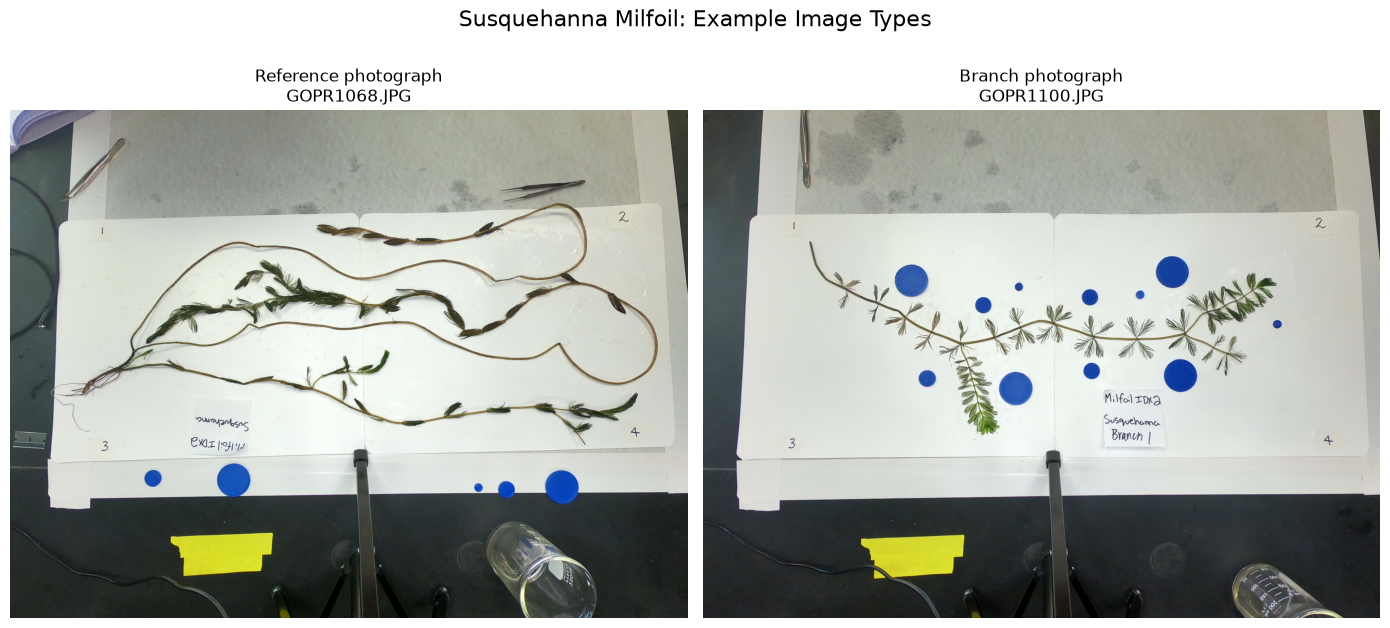

In [19]:
# Index the photographs by filename, without their extensions.
image_extensions = {".jpg", ".jpeg", ".png", ".tif", ".tiff"}

image_lookup = {
    path.stem.lower(): path
    for path in image_folder.rglob("*")
    if path.is_file() and path.suffix.lower() in image_extensions
}

fig, axes = plt.subplots(1, 2, figsize=(14, 7))

for ax, column, label in zip(
    axes,
    ["REFERENCE", "BRANCH"],
    ["Reference photograph", "Branch photograph"]
):
    # Find the first image listed in the table that exists in the folder.
    image_path = None

    for filename in morphmeasures[column].dropna().astype(str):
        image_key = Path(filename.strip()).stem.lower()
        if image_key in image_lookup:
            image_path = image_lookup[image_key]
            break

    if image_path is not None:
        with Image.open(image_path) as img:
            ax.imshow(img.convert("RGB"))
        ax.set_title(f"{label}\n{image_path.name}")
    else:
        ax.set_title(label)
        ax.text(
            0.5, 0.5, "No matching photograph found",
            ha="center", va="center", transform=ax.transAxes
        )

    ax.axis("off")

fig.suptitle("Susquehanna Milfoil: Example Image Types", fontsize=16)
plt.tight_layout()
plt.show()

### Plant Representation by Branch Number

This figure counts the unique plants represented at each lateral-branch
number. Repeated measurement rows do not increase the count. The primary
stem category includes every sampled plant, based on the sampling design,
rather than counting only explicitly labeled primary-stem records.
Branch numbers describe the recording order, not measured attachment height.

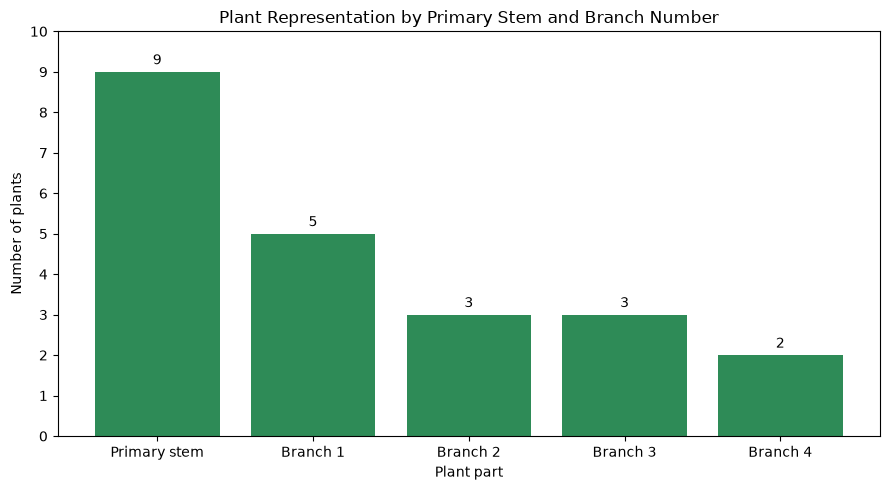

In [20]:
# Find the part_type column regardless of capitalization.
part_column = next(
    col for col in morphmeasures.columns
    if col.strip().lower() == "part_type"
)

part_type = (
    morphmeasures[part_column]
    .astype(str)
    .str.strip()
    .str.lower()
)

# Count plants with a primary-stem record.
# Each sampled plant has one primary stem, whether explicitly labeled or not.
stem_count = morphmeasures["IDX"].nunique()

# Count plants represented at each lateral-branch number.
lateral = morphmeasures.loc[
    part_type == "lateral_branch"
].copy()

lateral["BRANCHNUM"] = pd.to_numeric(
    lateral["BRANCHNUM"], errors="coerce"
)

branch_counts = (
    lateral.groupby("BRANCHNUM")["IDX"]
    .nunique()
    .sort_index()
)

labels = ["Primary stem"] + [
    f"Branch {int(number)}" for number in branch_counts.index
]
counts = [stem_count] + branch_counts.tolist()

fig, ax = plt.subplots(figsize=(9, 5))

bars = ax.bar(labels, counts, color="seagreen")
ax.bar_label(bars, padding=3)

ax.set_title("Plant Representation by Primary Stem and Branch Number")
ax.set_xlabel("Plant part")
ax.set_ylabel("Number of plants")
ax.set_ylim(0, max(counts) + 1)

from matplotlib.ticker import MaxNLocator
ax.yaxis.set_major_locator(MaxNLocator(integer=True))

plt.tight_layout()
plt.show()

### Calibrated Image Resolution

The summary and histogram describe variation in physical pixel size
across records in the loaded GoPro metadata table. Larger cm/pixel values
indicate coarser resolution. This explores image scale, not calibration
accuracy or uncertainty.

,Pixel size (cm/pixel)
count,26.000000
mean,0.021580
std,0.000420
min,0.020710
25%,0.021382
50%,0.021533
75%,0.021853
max,0.022351


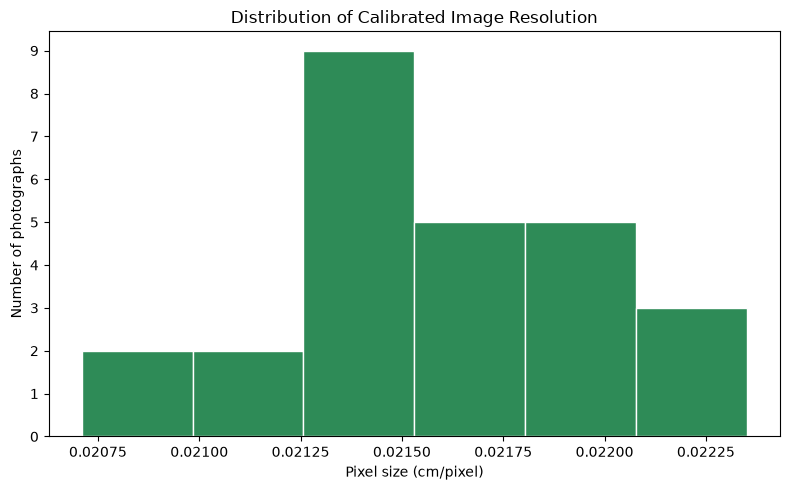

In [21]:
# Extract valid calibration values.
pixel_size = pd.to_numeric(
    gopro_metadata["MeanPixelSize_cmPerPixel"],
    errors="coerce"
).dropna()

pixel_size = pixel_size[pixel_size > 0]

# Summarize image resolution.
display(
    pixel_size.describe().to_frame(name="Pixel size (cm/pixel)")
)

# Plot the distribution across photographs.
fig, ax = plt.subplots(figsize=(8, 5))

ax.hist(pixel_size, bins="auto", color="seagreen", edgecolor="white")

ax.set_title("Distribution of Calibrated Image Resolution")
ax.set_xlabel("Pixel size (cm/pixel)")
ax.set_ylabel("Number of photographs")

from matplotlib.ticker import MaxNLocator
ax.yaxis.set_major_locator(MaxNLocator(integer=True))

plt.tight_layout()
plt.show()

The photographs have calibrated pixel sizes of approximately
0.0207–0.0224 cm/pixel, indicating modest variation in physical image
resolution. Larger values represent coarser resolution because each
pixel covers a greater physical distance.

Each photograph's corresponding mean pixel-area value will be used
to convert plant pixel counts into cm² before area measurements are
combined across photographs. This accounts for differences in image
scale, although it does not eliminate differences in the visibility
of fine plant structures.

### Data Integration & Overlap

#### Calibration Records

Image identifiers link REFERENCE & BRANCH in the morphology table to GOPROFILE in the metadata table. THe following summary checks whether each unique listed image has a calibration record, ignoring filename extensions and capitalization. It checks identifier overlap rather than whetehr calibration values are valid or unique

In [25]:
# Find available image files.
image_extensions = {".jpg", ".jpeg", ".png", ".tif", ".tiff"}

available_ids = {
    path.stem.upper()
    for path in image_folder.rglob("*")
    if path.is_file() and path.suffix.lower() in image_extensions
}

# Compare listed images with files in the folder.
file_summary = []

for column in ["REFERENCE", "BRANCH"]:
    listed_ids = set(
        morphmeasures[column].map(image_id).dropna()
    )
    listed_ids.discard("")

    missing = listed_ids - available_ids

    file_summary.append({
        "Image type": column,
        "Unique images listed": len(listed_ids),
        "Files found": len(listed_ids & available_ids),
        "Files missing": len(missing)
    })

    if missing:
        print(f"{column} — missing files: {sorted(missing)}")

display(pd.DataFrame(file_summary))

,Image type,Unique images listed,Files found,Files missing
0,REFERENCE,9,9,0
1,BRANCH,20,20,0


### RGB Brightness Exploration

#### Whole-Image Brightness Distributions

One available photograph listed in BRANCH is used for initial color
exploration. The histograms include every pixel: plant material, boards,
blue disks, shadows, writing, and equipment. Their peaks therefore do
not directly identify plant pixels. Brightness is displayed on the
8-bit scale from 0 to 255.

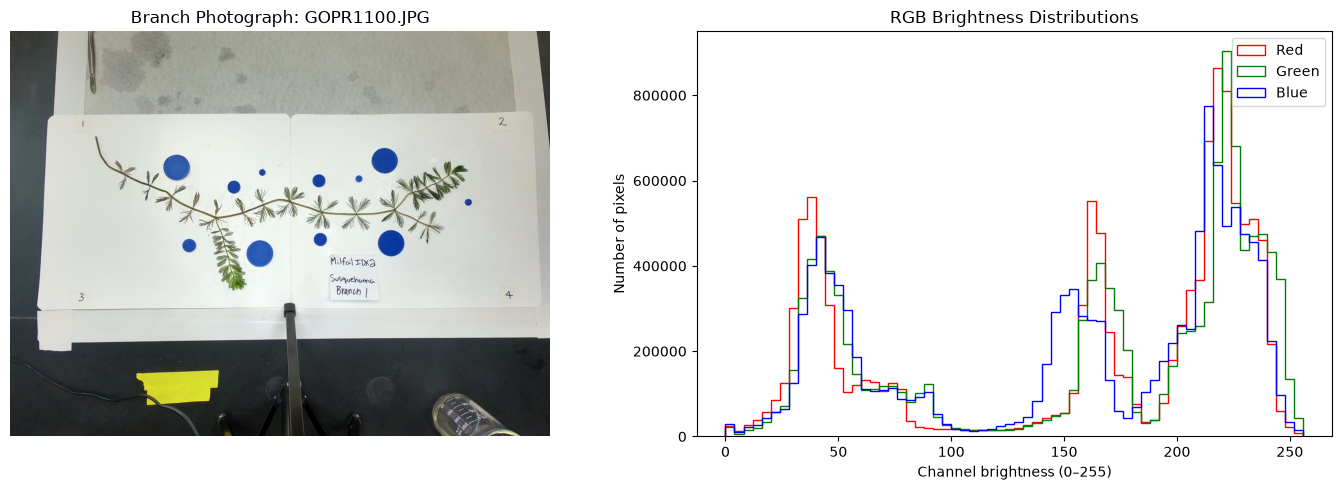

In [24]:
# Select the first available branch photograph.
branch_ids = (
    morphmeasures["BRANCH"]
    .map(image_id)
    .dropna()
)

example_id = next(
    identifier for identifier in branch_ids
    if identifier in available_ids
)

example_path = next(
    path for path in image_folder.rglob("*")
    if path.is_file()
    and path.suffix.lower() in image_extensions
    and path.stem.upper() == example_id
)

with Image.open(example_path) as img:
    rgb = np.array(img.convert("RGB"))

# Display the photograph and its RGB histograms.
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].imshow(rgb)
axes[0].set_title(f"Branch Photograph: {example_path.name}")
axes[0].axis("off")

for channel, color in enumerate(["red", "green", "blue"]):
    axes[1].hist(
        rgb[:, :, channel].ravel(),
        bins=64,
        range=(0, 256),
        histtype="step",
        color=color,
        label=color.capitalize()
    )

axes[1].set_title("RGB Brightness Distributions")
axes[1].set_xlabel("Channel brightness (0–255)")
axes[1].set_ylabel("Number of pixels")
axes[1].legend()

plt.tight_layout()
plt.show()

The RGB distributions contain several peaks, reflecting the different
surfaces and lighting conditions within the photograph. High-brightness
pixels likely correspond primarily to the white background boards,
while darker pixels include the tabletop, equipment, shadows, and plant
material. Because these distributions combine all objects in the image,
they do not establish whether plant and background pixels can be
separated. Comparing selected image regions will help assess their
color overlap.

### Spatial Patterns in Channel Brightness

The same photograph is displayed as separate red-, green-, and
blue-channel brightness maps. All panels use the same 0–255 scale.
The display colors represent intensity: blue indicates low brightness
and red indicates high brightness, regardless of the channel shown.
These maps locate brightness patterns that are combined in the histograms.

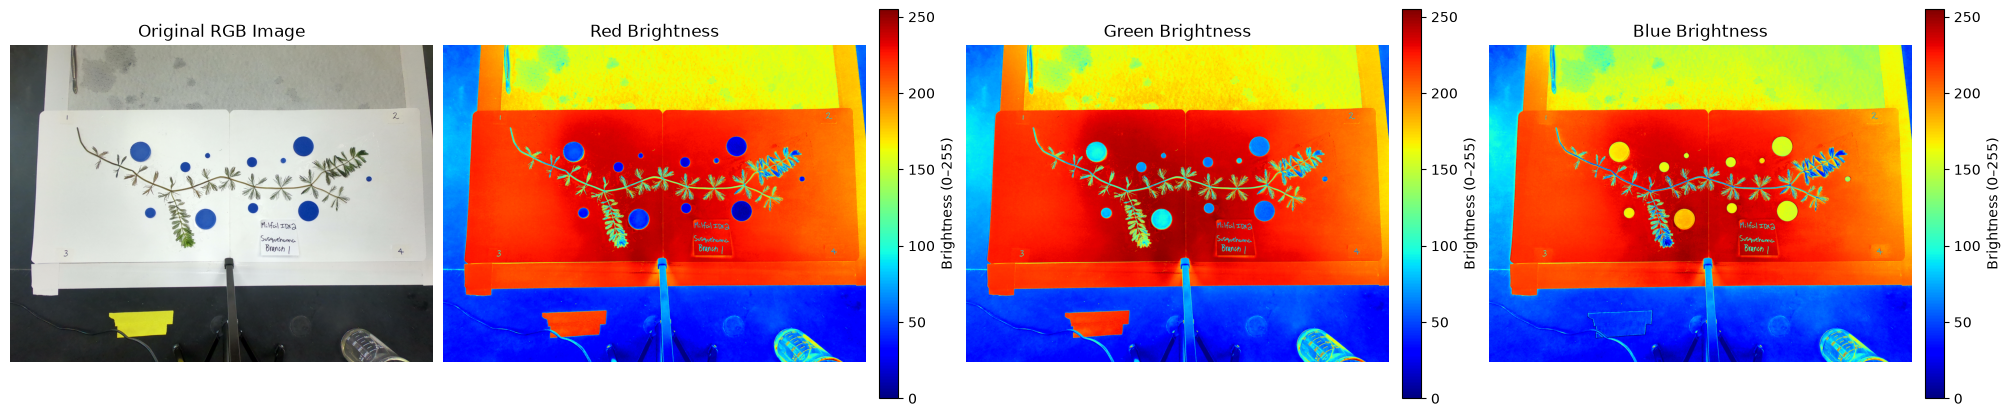

In [26]:
fig, axes = plt.subplots(
    1, 4,
    figsize=(20, 6),
    constrained_layout=True
)

# Original photograph.
axes[0].imshow(rgb)
axes[0].set_title("Original RGB Image")
axes[0].axis("off")

# Individual channels displayed using the same brightness scale.
for channel, name in enumerate(["Red", "Green", "Blue"]):
    ax = axes[channel + 1]

    im = ax.imshow(
        rgb[:, :, channel],
        cmap="jet",
        vmin=0,
        vmax=255
    )

    ax.set_title(f"{name} Brightness")
    ax.axis("off")

    colorbar = fig.colorbar(im, ax=ax, fraction=0.046, pad=0.03)
    colorbar.set_label("Brightness (0–255)")

plt.show()

The individual RGB brightness maps show that plant material generally
has lower channel brightness than the white background boards. However,
other objects also have low brightness, including the tabletop,
equipment, and writing. The blue reference disks show different
brightness patterns among channels, with higher blue than red brightness.

These patterns suggest that restricting analysis to a region around
the plant could reduce interference from unrelated objects. Further
comparison of plant, background, and shadow pixels is needed to assess
which channels provide the clearest separation.

### Implications for the Final Analysis

Before examining brightness values, each image will need to be cropped
or masked to remove unnecessary portions of the photograph while retaining
all plant tissue and the background immediately surrounding it. This will
focus the brightness distributions on the region relevant to plant
segmentation, rather than allowing distant background or unrelated objects
to dominate the pixel values. Within this region, selected plant, background,
and shadow areas will be compared to evaluate plant segmentation.

Final outputs will be total projected plant area and its vertical
distribution. 